In [8]:
import pathlib

print("Current working directory:", pathlib.Path().resolve())

Current working directory: /Users/lms/Documents/Forschung/textClust_hpo


# Comparison among algorithms

In [9]:
import pandas as pd
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from moocore import hypervolume

from smac_hpo.evaluation.utils import build_results_csv, store_results_csv, load_results_csv, normalize, pareto_optimal_points 
from smac_hpo.evaluation.utils import COLORS, COLOR_PALETTE, ALGORITHM_ORDER, OLD_DATASETS, NEW_DATASETS, ALL_DATASETS, NUM_SEEDS, NUM_REPS

In [10]:
full_opt_results_df = load_results_csv()
assert full_opt_results_df["dataset"].isin(ALL_DATASETS).all(), "Error: Some datasets in the results are not in the list of known datasets. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(OLD_DATASETS).any(), "Error: No old datasets found in the results. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(NEW_DATASETS).any(), "Error: No new datasets found in the results. Please check the dataset names."

for _, group in full_opt_results_df.groupby(["dataset"]):
    full_opt_results_df.loc[group.index, ["avg_throughput_normalized", "adj_mutual_info_final_normalized"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]].values


cv_results_df = full_opt_results_df[(full_opt_results_df["config_source"] == "cv") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()
default_results_df = full_opt_results_df[(full_opt_results_df["config_source"] == "default") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()
assert len(full_opt_results_df) != 0, "Error: No full optimization results found. Please run the full optimization first."

In [ ]:
results_ami = []
results_throughput = []

for n_seeds in NUM_SEEDS:
    for i in range(NUM_REPS):
        seeds = np.random.choice(cv_results_df["seed"].unique(), size=n_seeds, replace=False)
        subgroup = cv_results_df[cv_results_df["seed"].isin(seeds)].copy()
        test_group = subgroup[subgroup["is_test"] == True]
        train_group = subgroup[subgroup["is_test"] == False]
        df_mean_config_performance = (
            train_group.groupby(["config_id", "loo_datasets", "config", "algorithm"])[["adj_mutual_info_final", "avg_throughput_normalized"]]
            .mean()
            .reset_index()
        )
        idx_best_ami_train = (
            df_mean_config_performance
            .groupby(["loo_datasets", "algorithm"])["adj_mutual_info_final"]
            .idxmax()
        )
        idx_best_throughput_train = (
            df_mean_config_performance
            .groupby(["loo_datasets", "algorithm"])["avg_throughput_normalized"]
            .idxmax()
        )

        best_config_ids_ami_train = df_mean_config_performance.loc[idx_best_ami_train, "config_id"].values
        best_config_ids_throughput_train = df_mean_config_performance.loc[idx_best_throughput_train, "config_id"].values

        performance_best_configs_ami_on_test = (
            test_group[test_group["config_id"].isin(best_config_ids_ami_train)][["algorithm", "dataset", "adj_mutual_info_final"]]
        )
        performance_best_configs_throughput_on_test = (
            test_group[test_group["config_id"].isin(best_config_ids_throughput_train)][["algorithm", "dataset", "avg_throughput_normalized"]]
        )
        df = performance_best_configs_ami_on_test.copy()
        df["n_seeds"] = n_seeds
        df["n_reps"] = i
        df["seeds"] = str(seeds.tolist())
        results_ami.append(df)  
        
        df = performance_best_configs_throughput_on_test.copy()
        df["n_seeds"] = n_seeds
        df["n_reps"] = i
        df["seeds"] = str(seeds.tolist())
        results_throughput.append(df)     
        
best_ami_df: pd.DataFrame = pd.concat(results_ami, ignore_index=True)
best_throughput_df: pd.DataFrame = pd.concat(results_throughput, ignore_index=True)

display(best_ami_df)
display(best_throughput_df)


,algorithm,dataset,adj_mutual_info_final,n_seeds,n_reps,seeds
0,FSD,Arabic_Twitter,0.500234,1,0,[6.0]
1,FSD,Semantic40-T,0.741158,1,0,[6.0]
2,textClust,Arabic_Twitter,0.019648,1,0,[6.0]
3,textClust,Semantic40-T,0.584701,1,0,[6.0]
4,embClust,Arabic_Twitter,0.291624,1,0,[6.0]
...,...,...,...,...,...,...
21595,FSD,Semantic5-T,0.604594,10,44,"[2.0, 6.0, 5.0, 4.0, 10.0, 3.0, 1.0, 8.0, 7.0,..."
21596,textClust,CrisisLexT7,0.604082,10,44,"[2.0, 6.0, 5.0, 4.0, 10.0, 3.0, 1.0, 8.0, 7.0,..."
21597,textClust,Semantic5-T,0.651386,10,44,"[2.0, 6.0, 5.0, 4.0, 10.0, 3.0, 1.0, 8.0, 7.0,..."
21598,embClust,CrisisLexT7,0.627651,10,44,"[2.0, 6.0, 5.0, 4.0, 10.0, 3.0, 1.0, 8.0, 7.0,..."


,algorithm,dataset,avg_throughput_normalized,n_seeds,n_reps,seeds
0,textClust,Arabic_Twitter,0.915443,1,0,[6.0]
1,textClust,Semantic40-T,0.923938,1,0,[6.0]
2,FSD,Arabic_Twitter,0.976363,1,0,[6.0]
3,FSD,Semantic40-T,0.947610,1,0,[6.0]
4,embClust,Arabic_Twitter,0.392173,1,0,[6.0]
...,...,...,...,...,...,...
21595,FSD,Semantic5-T,0.914122,10,44,"[2.0, 6.0, 5.0, 4.0, 10.0, 3.0, 1.0, 8.0, 7.0,..."
21596,textClust,CrisisLexT7,0.964409,10,44,"[2.0, 6.0, 5.0, 4.0, 10.0, 3.0, 1.0, 8.0, 7.0,..."
21597,textClust,Semantic5-T,0.964354,10,44,"[2.0, 6.0, 5.0, 4.0, 10.0, 3.0, 1.0, 8.0, 7.0,..."
21598,embClust,CrisisLexT7,0.869415,10,44,"[2.0, 6.0, 5.0, 4.0, 10.0, 3.0, 1.0, 8.0, 7.0,..."


In [12]:
df = default_results_df.copy()
df["is_artificial"] = df["dataset"].str.contains("Semantic")

median_default_ami_df = (
    df.copy()
    .groupby(["algorithm", "is_artificial", "config_id"])[["adj_mutual_info_final", "avg_throughput_normalized"]]
    .mean()
    .reset_index()
    .groupby(["algorithm", "is_artificial"])[["adj_mutual_info_final", "avg_throughput_normalized"]]
    .max()
    .reset_index()
)
median_default_ami_df

,algorithm,is_artificial,adj_mutual_info_final,avg_throughput_normalized
0,FSD,False,0.488506,0.625893
1,FSD,True,0.475148,0.666799
2,embClust,False,0.272446,0.613121
3,embClust,True,0.743434,0.653429
4,textClust,False,0.508899,0.863903
5,textClust,True,0.387057,0.843944


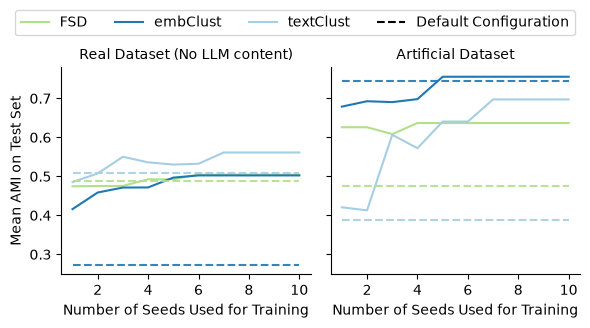

In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

df = best_ami_df.copy()
df["is_artificial"] = np.where(df["dataset"].str.contains("Semantic"), "Artificial Dataset", "Real Dataset (No LLM content)")

def draw_panel(data, **kwargs):
    ax = plt.gca()
    
    df = (
        data.groupby(["dataset", "n_seeds", "algorithm", "is_artificial"])["adj_mutual_info_final"]
        .median()
        .reset_index()
    )
    
    sns.lineplot(data=df, x="n_seeds", hue="algorithm", y="adj_mutual_info_final",
                 palette=COLORS, hue_order=ALGORITHM_ORDER, estimator="mean", errorbar=None, ax=ax)
    ax.set_ylabel("Mean AMI on Test Set")
    ax.set_xlabel("Number of Seeds Used for Training")
    ax.legend(title="Algorithm")
    is_artificial = df["is_artificial"].iloc[0] == "Artificial Dataset"
    for algorithm, median_ami in median_default_ami_df.loc[median_default_ami_df["is_artificial"] == is_artificial].set_index("algorithm")["adj_mutual_info_final"].items():
        ax.hlines(y=median_ami, xmin=1, xmax=10, color=COLORS[algorithm], linestyle="--", alpha=0.9,)

g = sns.FacetGrid(df, col="is_artificial", sharey=True)
g.map_dataframe(draw_panel)

# Change panel titles 
g.set_titles("{col_name}")

legend_handels = [
    Line2D([0], [0], color=COLORS["FSD"], label="FSD"),
    Line2D([0], [0], color=COLORS["embClust"], label="embClust"),
    Line2D([0], [0], color=COLORS["textClust"], label="textClust"),
    Line2D([0], [0], color="black", label="Default Configuration", linestyle="--")
]

g.figure.legend(
    handles=legend_handels,
    loc='upper center',
    ncol=4,
    bbox_to_anchor=(0.5, 1.1),
)
g.set_axis_labels("Number of Seeds Used for Training", "Mean AMI on Test Set")

#TODO: Number of clusters plot

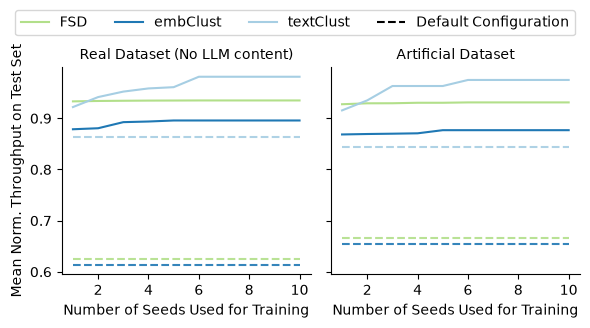

In [7]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

df = best_throughput_df.copy()
df["is_artificial"] = np.where(df["dataset"].str.contains("Semantic"), "Artificial Dataset", "Real Dataset (No LLM content)")

def draw_panel(data, **kwargs):
    ax = plt.gca()
    
    df = (
        data.groupby(["dataset", "n_seeds", "algorithm", "is_artificial"])["avg_throughput_normalized"]
        .median()
        .reset_index()
    )
    
    sns.lineplot(data=df, x="n_seeds", hue="algorithm", y="avg_throughput_normalized",
                 palette=COLORS, hue_order=ALGORITHM_ORDER, estimator="mean", errorbar=None, ax=ax)
    ax.set_ylabel("Mean Normalized Throughput on Test Set")
    ax.set_xlabel("Number of Seeds Used for Training")
    ax.legend(title="Algorithm")
    is_artificial = df["is_artificial"].iloc[0] == "Artificial Dataset"
    for algorithm, median_ami in median_default_ami_df.loc[median_default_ami_df["is_artificial"] == is_artificial].set_index("algorithm")["avg_throughput_normalized"].items():
        ax.hlines(y=median_ami, xmin=1, xmax=10, color=COLORS[algorithm], linestyle="--", alpha=0.9,)

g = sns.FacetGrid(df, col="is_artificial", sharey=True)
g.map_dataframe(draw_panel)

# Change panel titles 
g.set_titles("{col_name}")

legend_handels = [
    Line2D([0], [0], color=COLORS["FSD"], label="FSD"),
    Line2D([0], [0], color=COLORS["embClust"], label="embClust"),
    Line2D([0], [0], color=COLORS["textClust"], label="textClust"),
    Line2D([0], [0], color="black", label="Default Configuration", linestyle="--")
]

g.figure.legend(
    handles=legend_handels,
    loc='upper center',
    ncol=4,
    bbox_to_anchor=(0.5, 1.1),
)
g.set_axis_labels("Number of Seeds Used for Training", "Mean Norm. Throughput on Test Set")

# Number of Clusters

In [44]:
full_opt_results_df = load_results_csv()
assert full_opt_results_df["dataset"].isin(ALL_DATASETS).all(), "Error: Some datasets in the results are not in the list of known datasets. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(OLD_DATASETS).any(), "Error: No old datasets found in the results. Please check the dataset names."
assert full_opt_results_df["dataset"].isin(NEW_DATASETS).any(), "Error: No new datasets found in the results. Please check the dataset names."

for _, group in full_opt_results_df.groupby(["dataset"]):
    full_opt_results_df.loc[group.index, ["avg_throughput_normalized", "adj_mutual_info_final_normalized"]] = normalize(group, columns=["avg_throughput", "adj_mutual_info_final"], use_log=[True, False])[["avg_throughput", "adj_mutual_info_final"]].values


cv_results_df = full_opt_results_df[(full_opt_results_df["config_source"] == "cv") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()
default_results_df = full_opt_results_df[(full_opt_results_df["config_source"] == "default") & full_opt_results_df["dataset"].isin(NEW_DATASETS)].copy()
assert len(full_opt_results_df) != 0, "Error: No full optimization results found. Please run the full optimization first."

In [54]:
df = cv_results_df.copy()

for _, group in df.groupby(["dataset"]):
    df.loc[group.index, ["num_clusters_final_norm"]] = normalize(group, columns=["num_clusters_final"], use_log=[False])[["num_clusters_final"]].values

df = (df
      [df["is_test"] == True]
      [["algorithm", "dataset", "num_clusters_final_norm", "num_clusters_final"]]
      )

#sns.boxplot(df, x="num_clusters_final_norm", y="algorithm")

df = (df
      .groupby("algorithm")[["num_clusters_final"]]
      .mean()
      .reset_index())

df

,algorithm,num_clusters_final
0,FSD,4138.487385
1,embClust,1254.017760
2,textClust,3548.421760


algorithm,n_seeds,dataset,FSD,embClust,textClust,ranking
0,1,Arabic_7,0.375625,0.439376,0.388267,embClust
1,1,Arabic_Twitter,0.510767,0.400864,0.094460,FSD
2,1,CrisisLexT26,0.704604,0.614745,0.831399,textClust
3,1,CrisisLexT6,0.272203,0.302540,0.397525,textClust
4,1,CrisisLexT7,0.368792,0.495112,0.548235,textClust
...,...,...,...,...,...,...
155,10,MAVEN,0.077847,0.080918,0.005139,embClust
156,10,Mix_Data,0.577428,0.427219,0.708034,textClust
157,10,Semantic10-T,0.616926,0.817470,0.677710,embClust
158,10,Semantic40-T,0.688588,0.688784,0.762610,textClust


<Axes: xlabel='n_seeds', ylabel='Count'>

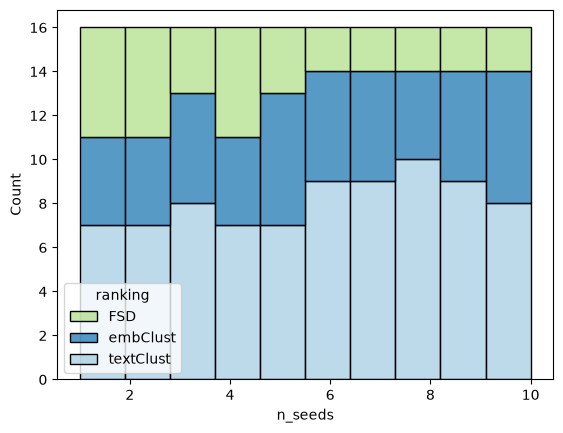

In [30]:
df = best_ami_df.copy()

assert isinstance(df, pd.DataFrame)

df = (
    df.groupby(["n_seeds", "algorithm", "dataset"])
    ["adj_mutual_info_final"]
    .mean()
    .reset_index()
    .pivot_table(values="adj_mutual_info_final", index=["n_seeds","dataset"], columns="algorithm")
    .reset_index()
)

df["ranking"] = df.apply(
    lambda row: row[["FSD", "embClust", "textClust"]].dropna().sort_values(ascending=False, kind="stable").index[0],
    axis=1,
)

display(df)

sns.histplot(df, x="n_seeds", hue="ranking", hue_order=ALGORITHM_ORDER, palette=COLORS, multiple="stack", bins=10)